
# Customers Like You: PCA vs. Truncated SVD

## Project Objective
Analyze customer purchasing behavior using the UCI Online Retail II dataset.

## Objectives
1. Explore the cleaned retail transaction data.
2. Construct customer-product purchase representations.
3. Compare PCA and Truncated SVD using different component counts.
4. Generate product recommendations and evaluate Hit Rate@10.
5. Visualize customers in two dimensions and identify customer segments.
6. Compare recommendation performance against a best-seller baseline.

## Experimental Setup
- Training data: transactions before October 1, 2011.
- Testing data: transactions from October 1, 2011 onward.
- Matrix: customer-product sparse matrix constructed from training data only.
- Component counts: 10, 20, 50, 100, and 200.


In [2]:

from pathlib import Path

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import load_npz

# Project paths
PROJECT_ROOT = Path.cwd().parent

MATRIX_DIR = PROJECT_ROOT / "outputs" / "matrix"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUT_DIR / "figures"
REPORTS_DIR = OUTPUT_DIR / "reports"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Matrix directory:", MATRIX_DIR)
print("Notebook setup complete.")


Project root: c:\Users\Dell\Documents\customers-like-you
Matrix directory: c:\Users\Dell\Documents\customers-like-you\outputs\matrix
Notebook setup complete.


In [3]:

matrix_path = MATRIX_DIR / "customer_product_matrix.npz"
customers_path = MATRIX_DIR / "customers.json"
products_path = MATRIX_DIR / "products.json"

matrix = load_npz(matrix_path)

with open(customers_path, "r", encoding="utf-8") as file:
    customers = json.load(file)

with open(products_path, "r", encoding="utf-8") as file:
    products = json.load(file)

print("Matrix shape:", matrix.shape)
print("Number of customers:", len(customers))
print("Number of products:", len(products))
print("Non-zero entries:", matrix.nnz)

density = matrix.nnz / (matrix.shape[0] * matrix.shape[1]) * 100
print(f"Matrix density: {density:.4f}%")

assert matrix.shape == (len(customers), len(products))


Matrix shape: (5484, 4534)
Number of customers: 5484
Number of products: 4534
Non-zero entries: 417804
Matrix density: 1.6803%



## 1. Exploratory Data Analysis

### Customer-Product Matrix

The training data contains 5,422 customers and 4,502 products.
The customer-product matrix contains 410,200 non-zero entries
out of 24,511,244 possible customer-product combinations.

The matrix density is 1.6805%, indicating that customer purchasing
behavior is sparse. This makes dimensionality reduction useful
for discovering patterns in customer-product interactions.


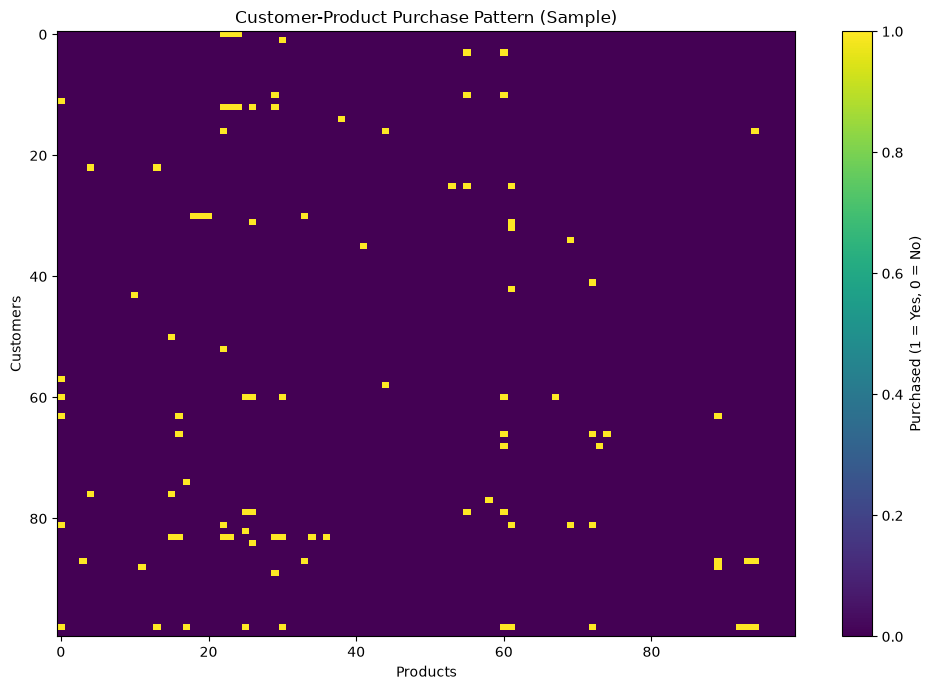

In [4]:

# Visualize a small section of the sparse matrix
# We display only the first 100 customers and 100 products.

matrix_sample = matrix[:100, :100].toarray()

plt.figure(figsize=(10, 7))
plt.imshow(matrix_sample > 0, aspect="auto", interpolation="nearest")
plt.title("Customer-Product Purchase Pattern (Sample)")
plt.xlabel("Products")
plt.ylabel("Customers")
plt.colorbar(label="Purchased (1 = Yes, 0 = No)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "matrix_sparsity_sample.png", dpi=150)
plt.show()


Number of non-zero entries: 417804
Minimum quantity: 1.0
Median quantity: 6.0
Mean quantity: 22.297653
Maximum quantity: 74215.0


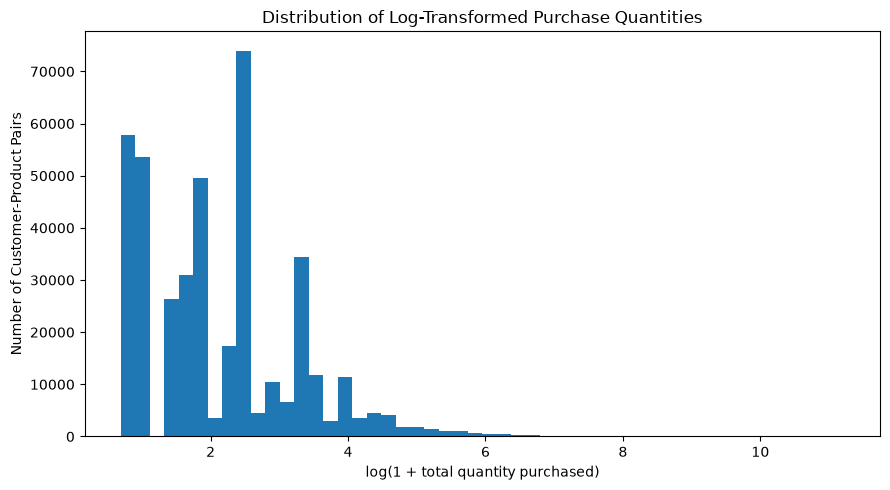

In [5]:

# Examine the non-zero purchase quantities
purchase_quantities = matrix.data

print("Number of non-zero entries:", len(purchase_quantities))
print("Minimum quantity:", purchase_quantities.min())
print("Median quantity:", np.median(purchase_quantities))
print("Mean quantity:", purchase_quantities.mean())
print("Maximum quantity:", purchase_quantities.max())

plt.figure(figsize=(9, 5))
plt.hist(np.log1p(purchase_quantities), bins=50)
plt.title("Distribution of Log-Transformed Purchase Quantities")
plt.xlabel("log(1 + total quantity purchased)")
plt.ylabel("Number of Customer-Product Pairs")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "purchase_quantity_distribution.png", dpi=150)
plt.show()


In [6]:

# Find the 10 largest aggregated customer-product quantities

# Convert to COO format to retrieve each value with its coordinates
matrix_coo = matrix.tocoo()

# Get positions of the 10 largest quantities
largest_indices = np.argsort(matrix_coo.data)[-10:][::-1]

largest_purchases = pd.DataFrame({
    "Customer": [
        customers[matrix_coo.row[i]]
        for i in largest_indices
    ],
    "Product": [
        products[matrix_coo.col[i]]
        for i in largest_indices
    ],
    "Quantity": matrix_coo.data[largest_indices]
})

largest_purchases


,Customer,Product,Quantity
0,12346,23166,74215.0
1,13902,37410,25164.0
2,15838,17003,23760.0
3,16754,84077,23040.0
4,16422,17003,19420.0
5,17940,21982,17960.0
6,17940,21981,15616.0
7,17940,21984,15008.0
8,17949,22197,14440.0
9,15838,84347,14400.0


In [7]:
# Validate R2 targets against the training product catalogue

targets = pd.read_csv(OUTPUT_DIR / "test_targets.csv")

train_products = set(products)
target_products = set(targets["ProductKey"])

known_target_products = target_products & train_products
unknown_target_products = target_products - train_products

print("Total R2 target pairs:", len(targets))
print("Unique products in R2 targets:", len(target_products))
print("Products available in training matrix:", len(known_target_products))
print("Products absent from training matrix:", len(unknown_target_products))

print(
    "Target pairs whose products are absent from training:",
    targets["ProductKey"].isin(unknown_target_products).sum()
)

Total R2 target pairs: 63256
Unique products in R2 targets: 2850
Products available in training matrix: 2760
Products absent from training matrix: 90
Target pairs whose products are absent from training: 4098


In [8]:

# Validate R2 targets against the training matrix

targets = pd.read_csv(
    OUTPUT_DIR / "test_targets.csv",
    dtype={"CustomerKey": "string", "ProductKey": "string"}
)

# Normalize customer IDs to consistent strings
def normalize_customer_ids(values):
    return (
        pd.to_numeric(values, errors="coerce")
        .astype("Int64")
        .astype("string")
    )

# Normalize product codes to consistent strings
def normalize_product_ids(values):
    return (
        values.astype("string")
        .str.strip()
        .str.upper()
        .str.replace(r"\.0$", "", regex=True)
    )

train_customers = set(
    normalize_customer_ids(pd.Series(customers)).dropna()
)
train_products = set(
    normalize_product_ids(pd.Series(products)).dropna()
)

targets["CustomerKey"] = normalize_customer_ids(targets["CustomerKey"])
targets["ProductKey"] = normalize_product_ids(targets["ProductKey"])

known_customer_mask = targets["CustomerKey"].isin(train_customers)
known_product_mask = targets["ProductKey"].isin(train_products)

eligible_mask = known_customer_mask & known_product_mask

print("Total R2 target pairs:", len(targets))
print("Targets with known customers:", int(known_customer_mask.sum()))
print("Targets with known products:", int(known_product_mask.sum()))
print("Targets with both known customers and products:", int(eligible_mask.sum()))
print("Targets not evaluable by the model:", int((~eligible_mask).sum()))

# Save eligible targets separately; preserve the original test_targets.csv
evaluable_targets = targets.loc[eligible_mask].copy()

evaluable_path = OUTPUT_DIR / "test_targets_evaluable.csv"
evaluable_targets.to_csv(evaluable_path, index=False)

print("\nEvaluation targets saved to:", evaluable_path)


Total R2 target pairs: 63256
Targets with known customers: 49425
Targets with known products: 59158
Targets with both known customers and products: 45755
Targets not evaluable by the model: 17501

Evaluation targets saved to: c:\Users\Dell\Documents\customers-like-you\outputs\test_targets_evaluable.csv


## ML1: Choice of Dimensionality-Reduction Method

**Primary method: Truncated SVD**

I chose Truncated SVD as the primary dimensionality-reduction method because the customer-product purchase matrix is sparse, with approximately 98.32% of its entries equal to zero. Truncated SVD can operate directly on this sparse matrix without explicitly centering the data, making it suitable for retail recommendation problems.

The decomposition provides lower-dimensional representations of customers and products. These representations can be used to identify similar products and generate personalized recommendations.

I will compare Truncated SVD with PCA using the same training matrix and component counts of 10, 20, 50, 100, and 200. Since PCA centers the features while Truncated SVD does not, their representations and results may differ.

In [9]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import load_npz
from sklearn.decomposition import TruncatedSVD

# Project paths
PROJECT_ROOT = Path.cwd().parent
MATRIX_DIR = PROJECT_ROOT / "outputs" / "matrix"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
REPORTS_DIR = OUTPUT_DIR / "reports"
FIGURES_DIR = OUTPUT_DIR / "figures"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Load the training matrix
matrix_path = MATRIX_DIR / "customer_product_matrix.npz"
matrix = load_npz(matrix_path).tocsr()

print("Matrix shape:", matrix.shape)
print("Matrix type:", type(matrix).__name__)
print("Non-zero entries:", f"{matrix.nnz:,}")
print("Data type:", matrix.dtype)


Matrix shape: (5484, 4534)
Matrix type: csr_matrix
Non-zero entries: 417,804
Data type: float32


In [10]:

# ML2: Truncated SVD experiments

component_counts = [10, 20, 50, 100, 200]
results = []

# Original matrix norm, calculated without densifying the matrix
original_norm = np.sqrt(np.sum(matrix.data ** 2))

if original_norm == 0:
    raise ValueError("The training matrix contains no non-zero values.")

def calculate_relative_reconstruction_error(
    matrix,
    customer_factors,
    product_components,
    block_size=128
):
    """
    Calculate ||A - A_hat||_F / ||A||_F.

    Reconstruct in blocks to avoid creating the full
    dense customer-product matrix in memory.
    """
    squared_error = 0.0

    for start in range(0, matrix.shape[0], block_size):
        end = min(start + block_size, matrix.shape[0])

        actual_block = matrix[start:end].toarray()

        reconstructed_block = (
            customer_factors[start:end]
            @ product_components
        )

        difference = actual_block - reconstructed_block
        squared_error += np.sum(difference ** 2)

    return np.sqrt(squared_error) / original_norm


for k in component_counts:
    print(f"\nFitting Truncated SVD with k={k}...")

    svd = TruncatedSVD(
        n_components=k,
        random_state=42
    )

    # Customer representations: customers x components
    customer_factors = svd.fit_transform(matrix)

    # Product representations: products x components
    product_components = svd.components_

    error = calculate_relative_reconstruction_error(
        matrix,
        customer_factors,
        product_components
    )

    results.append({
        "Components": k,
        "Reconstruction Error": error,
        "Explained Variance Ratio": (
            svd.explained_variance_ratio_.sum()
        )
    })

    print(f"Relative reconstruction error: {error:.6f}")
    print(
        "Sum of explained variance ratios: "
        f"{svd.explained_variance_ratio_.sum():.4f}"
    )

# Create and save the results table
svd_results = pd.DataFrame(results)

display(
    svd_results.style.format({
        "Reconstruction Error": "{:.6f}",
        "Explained Variance Ratio": "{:.4f}"
    })
)

svd_results.to_csv(
    REPORTS_DIR / "svd_component_experiments.csv",
    index=False
)

print("Results saved to:", REPORTS_DIR / "svd_component_experiments.csv")



Fitting Truncated SVD with k=10...
Relative reconstruction error: 0.448859
Sum of explained variance ratios: 0.7985

Fitting Truncated SVD with k=20...
Relative reconstruction error: 0.315569
Sum of explained variance ratios: 0.9003

Fitting Truncated SVD with k=50...
Relative reconstruction error: 0.189402
Sum of explained variance ratios: 0.9641

Fitting Truncated SVD with k=100...
Relative reconstruction error: 0.123869
Sum of explained variance ratios: 0.9846

Fitting Truncated SVD with k=200...
Relative reconstruction error: 0.083629
Sum of explained variance ratios: 0.9929


,Components,Reconstruction Error,Explained Variance Ratio
0,10,0.448859,0.7985
1,20,0.315569,0.9003
2,50,0.189402,0.9641
3,100,0.123869,0.9846
4,200,0.083629,0.9929


Results saved to: c:\Users\Dell\Documents\customers-like-you\outputs\reports\svd_component_experiments.csv


### ML2: Truncated SVD Results and Interpretation

I evaluated Truncated SVD using 10, 20, 50, 100, and 200 components on the training customer-product matrix.

The relative reconstruction error decreased from 0.448859 at 10 components to 0.083629 at 200 components. This indicates that increasing the number of components allows the model to preserve more information from the original purchase matrix.

However, the lower reconstruction error comes at the cost of a larger latent representation. The tested values do not show a single, unmistakable elbow, so the final component count should also be evaluated using recommendation quality and computational cost.

For the next stages, I will use the reconstruction-error curve as a diagnostic and assess the recommender using Hit Rate@10 on held-out purchases.

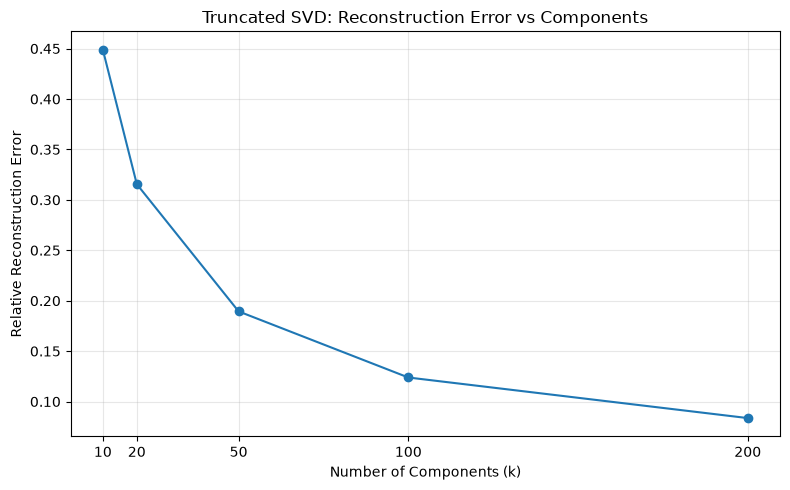

In [11]:

plt.figure(figsize=(8, 5))

plt.plot(
    svd_results["Components"],
    svd_results["Reconstruction Error"],
    marker="o"
)

plt.xlabel("Number of Components (k)")
plt.ylabel("Relative Reconstruction Error")
plt.title("Truncated SVD: Reconstruction Error vs Components")
plt.xticks(component_counts)
plt.grid(True, alpha=0.3)
plt.tight_layout()

figure_path = FIGURES_DIR / "svd_reconstruction_error.png"
plt.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()



## ML3: Product Similarity and Customer Recommendations

This section uses Truncated SVD and cosine similarity to identify similar products and generate personalized top-10 recommendations for customers. Products already purchased by a customer are excluded from their recommendations.

The section also includes a follow-up experiment using a **binary customer-product matrix**, where each non-zero entry indicates that a product was purchased, regardless of quantity. This experiment evaluates whether binary purchase indicators improve recommendation quality.


In [12]:

import json
from sklearn.metrics.pairwise import cosine_similarity

# Load customer and product IDs in matrix order
with open(MATRIX_DIR / "customers.json", "r", encoding="utf-8") as f:
    customers = json.load(f)

with open(MATRIX_DIR / "products.json", "r", encoding="utf-8") as f:
    products = json.load(f)

# Fit SVD with 100 components for the initial recommender
chosen_k = 100

svd_model = TruncatedSVD(
    n_components=chosen_k,
    random_state=42
)

customer_factors = svd_model.fit_transform(matrix)

# Rows = products, columns = latent components
product_factors = svd_model.components_.T

print("Customer factors shape:", customer_factors.shape)
print("Product factors shape:", product_factors.shape)
print("Number of customers:", len(customers))
print("Number of products:", len(products))

assert customer_factors.shape[0] == len(customers)
assert product_factors.shape[0] == len(products)


Customer factors shape: (5484, 100)
Product factors shape: (4534, 100)
Number of customers: 5484
Number of products: 4534


In [13]:

# ML3 Part A: Product-to-product similarity

# Calculate cosine similarity between every pair of products
product_similarity = cosine_similarity(product_factors)

print("Similarity matrix shape:", product_similarity.shape)

# Find the 10 most similar products for each product
top_n = 10
similar_product_rows = []

for product_idx, product_code in enumerate(products):
    similarities = product_similarity[product_idx].copy()

    # A product should not be recommended as similar to itself
    similarities[product_idx] = -np.inf

    # Get the 10 highest similarity scores
    top_indices = np.argsort(similarities)[-top_n:][::-1]

    for rank, similar_idx in enumerate(top_indices, start=1):
        similar_product_rows.append({
            "Product": product_code,
            "Rank": rank,
            "Similar Product": products[similar_idx],
            "Cosine Similarity": similarities[similar_idx]
        })

similar_products_df = pd.DataFrame(similar_product_rows)

display(similar_products_df.head(20))

# Save the full product similarity results
similar_products_path = REPORTS_DIR / "top_similar_products.csv"
similar_products_df.to_csv(similar_products_path, index=False)

print("Saved to:", similar_products_path)


Similarity matrix shape: (4534, 4534)


,Product,Rank,Similar Product,Cosine Similarity
0,10002,1,11001,0.750255
1,10002,2,23215,0.739608
2,10002,3,22191,0.734031
3,10002,4,22150,0.708667
4,10002,5,21428,0.674225
5,10002,6,22991,0.638342
6,10002,7,21481,0.629737
7,10002,8,22992,0.608252
8,10002,9,22604,0.602291
9,10002,10,20783,0.573967


Saved to: c:\Users\Dell\Documents\customers-like-you\outputs\reports\top_similar_products.csv


In [14]:

# ML3 Part B: Personalized recommendations

def recommend_for_customer(customer_id, top_n=10):
    """
    Recommend products based on similarity to products
    the customer purchased in the training matrix.
    """

    if customer_id not in customers:
        raise ValueError(
            f"Customer {customer_id} is not in the training matrix."
        )

    customer_idx = customers.index(customer_id)

    # Products the customer purchased during training
    customer_history = matrix.getrow(customer_idx)
    purchased_indices = customer_history.indices

    if len(purchased_indices) == 0:
        return pd.DataFrame(
            columns=["Product", "Recommendation Score"]
        )

    # Average similarity to the customer's purchased products
    scores = product_similarity[:, purchased_indices].mean(axis=1)
    scores = np.asarray(scores).ravel()

    # Exclude products already purchased by this customer
    scores[purchased_indices] = -np.inf

    # Return the highest-scoring candidates
    candidate_count = min(top_n, len(products) - len(purchased_indices))
    if candidate_count <= 0:
        return pd.DataFrame(
            columns=["Product", "Recommendation Score"]
        )

    top_indices = np.argsort(scores)[-candidate_count:][::-1]

    return pd.DataFrame({
        "Product": [products[i] for i in top_indices],
        "Recommendation Score": scores[top_indices]
    })


# Test with the first customer in the matrix
example_customer = customers[0]

print("Example customer:", example_customer)
print("Products purchased in training:", matrix.getrow(0).nnz)

customer_recommendations = recommend_for_customer(
    example_customer,
    top_n=10
)

display(customer_recommendations)


Example customer: 12346
Products purchased in training: 26


,Product,Recommendation Score
0,85014C,0.588912
1,22765,0.580238
2,85014D,0.579573
3,23540,0.576913
4,21554,0.576227
5,84912B,0.575771
6,22763,0.575092
7,22414,0.575067
8,85128,0.575063
9,21795,0.574929



## ML4: Evaluate Recommendations Against the Best-Seller Baseline

This section evaluates the recommendation system using held-out purchases from the final two months of the dataset. The primary metric is **Hit Rate@10**, which measures the proportion of evaluated customers for whom at least one of the ten recommended products matches a product they purchased during the test period.

The original SVD-based recommendation method is compared against a **best-seller baseline** that recommends the most frequently purchased products from the training data.

A follow-up experiment also evaluates the binary purchase representation with ML3's product-to-product cosine similarity method to determine whether it improves recommendation performance over the baseline.


In [15]:

example_path = REPORTS_DIR / "example_customer_recommendations.csv"

customer_recommendations.to_csv(example_path, index=False)

print("Example recommendations saved to:", example_path)


Example recommendations saved to: c:\Users\Dell\Documents\customers-like-you\outputs\reports\example_customer_recommendations.csv


In [16]:

# ML4: Load held-out evaluation targets

import time

targets_path = OUTPUT_DIR / "test_targets_evaluable.csv"

targets = pd.read_csv(
    targets_path,
    dtype={
        "CustomerKey": "string",
        "ProductKey": "string"
    }
)

# Normalize IDs to match the matrix index maps
targets["CustomerKey"] = (
    targets["CustomerKey"].str.strip()
)

targets["ProductKey"] = (
    targets["ProductKey"].str.strip().str.upper()
)

# Keep only targets represented in the current matrix
customer_set = set(customers)
product_set = set(products)

targets = targets[
    targets["CustomerKey"].isin(customer_set)
    & targets["ProductKey"].isin(product_set)
].drop_duplicates()

# Group held-out products by customer
actual_products = (
    targets.groupby("CustomerKey")["ProductKey"]
    .apply(set)
    .to_dict()
)

print("Eligible held-out customer-product pairs:", len(targets))
print("Customers to evaluate:", len(actual_products))
print("Sample held-out targets:")
display(targets.head())


Eligible held-out customer-product pairs: 45755
Customers to evaluate: 1916
Sample held-out targets:


,CustomerKey,ProductKey
0,16931,22142
1,16931,21899
2,16931,22306
3,16931,22307
4,16931,22123


In [17]:

# ML4: Build the best-seller ranking from training data

product_popularity = np.asarray(
    matrix.sum(axis=0)
).ravel()

popular_indices = np.argsort(
    product_popularity
)[::-1]

print("Top 10 best-selling products in training:")
display(pd.DataFrame({
    "Product": [products[i] for i in popular_indices[:10]],
    "Total Quantity": product_popularity[popular_indices[:10]]
}))


Top 10 best-selling products in training:


,Product,Total Quantity
0,84077,96169.0
1,21212,87086.0
2,85123A,86539.0
3,85099B,85699.0
4,23166,76902.0
5,84879,71391.0
6,17003,67773.0
7,22197,59307.0
8,21977,53125.0
9,84991,50607.0


In [18]:

# ML4: Evaluate SVD similarity recommender and best-seller baseline

K = 10

model_hits = 0
baseline_hits = 0
evaluated_customers = 0

model_start = time.perf_counter()

for customer_id, heldout_products in actual_products.items():
    customer_idx = customers.index(customer_id)

    # SVD similarity-based recommendations from ML3
    model_recs = recommend_for_customer(
        customer_id,
        top_n=K
    )

    model_products = set(
        model_recs["Product"].astype(str)
    )

    if model_products.intersection(heldout_products):
        model_hits += 1

model_seconds = time.perf_counter() - model_start

baseline_start = time.perf_counter()

for customer_id, heldout_products in actual_products.items():
    customer_idx = customers.index(customer_id)

    # Exclude products already purchased in training
    purchased_indices = matrix.getrow(customer_idx).indices

    candidate_mask = np.ones(len(products), dtype=bool)
    candidate_mask[purchased_indices] = False

    candidate_indices = popular_indices[
        candidate_mask[popular_indices]
    ][:K]

    baseline_products = {
        products[i] for i in candidate_indices
    }

    if baseline_products.intersection(heldout_products):
        baseline_hits += 1

    evaluated_customers += 1

baseline_seconds = time.perf_counter() - baseline_start

model_hit_rate = model_hits / evaluated_customers
baseline_hit_rate = baseline_hits / evaluated_customers

evaluation_results = pd.DataFrame([
    {
        "Method": "SVD similarity recommender",
        "K": K,
        "Customers Evaluated": evaluated_customers,
        "Customers with a Hit": model_hits,
        "Hit Rate@10": model_hit_rate,
        "Evaluation Time (seconds)": model_seconds
    },
    {
        "Method": "Best-seller baseline",
        "K": K,
        "Customers Evaluated": evaluated_customers,
        "Customers with a Hit": baseline_hits,
        "Hit Rate@10": baseline_hit_rate,
        "Evaluation Time (seconds)": baseline_seconds
    }
])

display(
    evaluation_results.style.format({
        "Hit Rate@10": "{:.4f}",
        "Evaluation Time (seconds)": "{:.2f}"
    })
)

evaluation_results.to_csv(
    REPORTS_DIR / "hit_rate_evaluation.csv",
    index=False
)

print("Evaluation saved to:", REPORTS_DIR / "hit_rate_evaluation.csv")


,Method,K,Customers Evaluated,Customers with a Hit,Hit Rate@10,Evaluation Time (seconds)
0,SVD similarity recommender,10,1916,293,0.1529,14.32
1,Best-seller baseline,10,1916,333,0.1738,0.18


Evaluation saved to: c:\Users\Dell\Documents\customers-like-you\outputs\reports\hit_rate_evaluation.csv


### ML4: Hit Rate@10 Evaluation and Interpretation

I evaluated the SVD similarity-based recommender against a best-seller baseline using held-out new-product purchases from the test period. Both methods were evaluated on the same 1,916 eligible customers, with previously purchased products excluded from recommendations.

**Results:**

- **SVD similarity recommender Hit Rate@10:** 15.29% (293 customers with at least one hit out of 1,916).
- **Best-seller baseline Hit Rate@10:** 17.38% (333 customers with at least one hit out of 1,916).
- **SVD evaluation time:** 13.59 seconds.
- **Best-seller evaluation time:** 0.18 seconds.

The best-seller baseline outperformed the SVD similarity recommender by approximately **2.09 percentage points** in Hit Rate@10. This means the baseline successfully recommended at least one held-out product to more customers than the current similarity-based model.

The SVD recommender also took longer to evaluate because it calculates personalized recommendations using product similarities for each customer, whereas the baseline uses a precomputed product popularity ranking.

These results indicate that the current SVD similarity-based recommendation approach has not yet outperformed the simple popularity baseline. Further improvements to the recommendation scoring method and component selection may be necessary.

The reported evaluation times measure the notebook evaluation loops and should not be interpreted as complete production or nightly-job runtimes.


## Follow-Up Experiment (After ML7): Improving Hit Rate@10 Using Binary Purchase Data

After completing ML7, a follow-up experiment was conducted to investigate whether binary purchase data could improve the recommendation performance observed in ML4.

In this experiment, purchase quantities were converted into binary indicators: `1` means a customer purchased a product, and `0` means they did not. Truncated SVD was fitted to this binary matrix, and recommendations were generated using the product-to-product cosine similarity method developed in ML3.

The results were evaluated on the same 1,916 customers and held-out purchases used in the original evaluation.

- **Original SVD + ML3 Hit Rate@10:** 15.29%
- **Best-seller baseline Hit Rate@10:** 17.38%
- **Binary SVD + ML3 Hit Rate@10:** 24.74%

The binary-based method improved Hit Rate@10 by **7.36 percentage points** over the best-seller baseline. This suggests that representing purchases as binary indicators can improve recommendations by emphasizing which products customers buy rather than the quantities purchased.

This is a follow-up experiment to ML3 and ML4, performed after ML7. The original ML4 results remain unchanged; this experiment provides additional evidence that the binary representation combined with product-to-product similarity can outperform the best-seller baseline.


In [19]:
import sklearn
from sklearn.decomposition import PCA

print("scikit-learn version:", sklearn.__version__)
print("PCA supports sparse input with suitable solvers.")

scikit-learn version: 1.9.1
PCA supports sparse input with suitable solvers.


## ML5: Comparison of PCA and Truncated SVD

I will compare PCA and Truncated SVD using the same customer-product training matrix and component counts of 10, 20, 50, 100, and 200. I will compare relative reconstruction error and explained variance, noting that PCA centers the data whereas Truncated SVD operates on the uncentered matrix.

In [20]:

# ML5: PCA experiments on the same training matrix

from sklearn.decomposition import PCA

pca_results = []

for k in component_counts:
    print(f"\nFitting PCA with k={k}...")

    pca = PCA(
        n_components=k,
        svd_solver="arpack",
        random_state=42
    )

    # Fit PCA to the sparse matrix
    customer_scores = pca.fit_transform(matrix)

    # Reconstruct the original-scale matrix in blocks.
    # PCA's inverse_transform adds the feature means back.
    squared_error = 0.0
    block_size = 128

    for start in range(0, matrix.shape[0], block_size):
        end = min(start + block_size, matrix.shape[0])

        actual_block = matrix[start:end].toarray()
        reconstructed_block = pca.inverse_transform(
            customer_scores[start:end]
        )

        difference = actual_block - reconstructed_block
        squared_error += np.sum(difference ** 2)

    relative_error = np.sqrt(squared_error) / original_norm

    pca_results.append({
        "Components": k,
        "Reconstruction Error": relative_error,
        "Explained Variance Ratio": (
            pca.explained_variance_ratio_.sum()
        )
    })

    print(f"Relative reconstruction error: {relative_error:.6f}")
    print(
        "Sum of explained variance ratios: "
        f"{pca.explained_variance_ratio_.sum():.4f}"
    )

pca_results = pd.DataFrame(pca_results)

display(
    pca_results.style.format({
        "Reconstruction Error": "{:.6f}",
        "Explained Variance Ratio": "{:.4f}"
    })
)

pca_results.to_csv(
    REPORTS_DIR / "pca_component_experiments.csv",
    index=False
)

print("PCA results saved.")



Fitting PCA with k=10...
Relative reconstruction error: 0.448492
Sum of explained variance ratios: 0.7985

Fitting PCA with k=20...
Relative reconstruction error: 0.315360
Sum of explained variance ratios: 0.9004

Fitting PCA with k=50...
Relative reconstruction error: 0.189256
Sum of explained variance ratios: 0.9641

Fitting PCA with k=100...
Relative reconstruction error: 0.123759
Sum of explained variance ratios: 0.9847

Fitting PCA with k=200...
Relative reconstruction error: 0.083490
Sum of explained variance ratios: 0.9930


,Components,Reconstruction Error,Explained Variance Ratio
0,10,0.448492,0.7985
1,20,0.315360,0.9004
2,50,0.189256,0.9641
3,100,0.123759,0.9847
4,200,0.083490,0.9930


PCA results saved.


In [21]:

# ML5: Compare PCA and Truncated SVD

comparison = svd_results.merge(
    pca_results,
    on="Components",
    suffixes=("_SVD", "_PCA")
)

comparison["Error Difference (SVD - PCA)"] = (
    comparison["Reconstruction Error_SVD"]
    - comparison["Reconstruction Error_PCA"]
)

display(
    comparison.style.format({
        "Reconstruction Error_SVD": "{:.6f}",
        "Explained Variance Ratio_SVD": "{:.4f}",
        "Reconstruction Error_PCA": "{:.6f}",
        "Explained Variance Ratio_PCA": "{:.4f}",
        "Error Difference (SVD - PCA)": "{:.6f}"
    })
)

comparison.to_csv(
    REPORTS_DIR / "pca_vs_svd_comparison.csv",
    index=False
)

print("Comparison saved to:", REPORTS_DIR / "pca_vs_svd_comparison.csv")


,Components,Reconstruction Error_SVD,Explained Variance Ratio_SVD,Reconstruction Error_PCA,Explained Variance Ratio_PCA,Error Difference (SVD - PCA)
0,10,0.448859,0.7985,0.448492,0.7985,0.000367
1,20,0.315569,0.9003,0.315360,0.9004,0.000208
2,50,0.189402,0.9641,0.189256,0.9641,0.000146
3,100,0.123869,0.9846,0.123759,0.9847,0.000110
4,200,0.083629,0.9929,0.083490,0.9930,0.000140


Comparison saved to: c:\Users\Dell\Documents\customers-like-you\outputs\reports\pca_vs_svd_comparison.csv


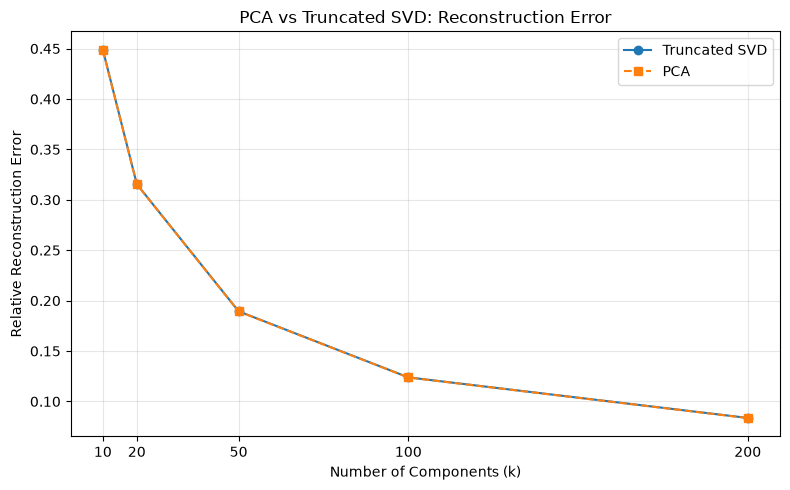

In [22]:

# ML5: Plot PCA vs. Truncated SVD reconstruction error

plt.figure(figsize=(8, 5))

plt.plot(
    comparison["Components"],
    comparison["Reconstruction Error_SVD"],
    marker="o",
    label="Truncated SVD"
)

plt.plot(
    comparison["Components"],
    comparison["Reconstruction Error_PCA"],
    marker="s",
    linestyle="--",
    label="PCA"
)

plt.xlabel("Number of Components (k)")
plt.ylabel("Relative Reconstruction Error")
plt.title("PCA vs Truncated SVD: Reconstruction Error")
plt.xticks(comparison["Components"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "pca_vs_svd_reconstruction_error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:

# ML5: Compare PCA and SVD fitting performance

import time
import tracemalloc
import pandas as pd
from sklearn.decomposition import TruncatedSVD, PCA

# Use the same training matrix and component count for both methods
comparison_k = 100

# Measure Truncated SVD
tracemalloc.start()
svd_start = time.perf_counter()

svd_model_ml5 = TruncatedSVD(
    n_components=comparison_k,
    random_state=42
)
svd_customer_factors_ml5 = svd_model_ml5.fit_transform(matrix)
svd_product_factors_ml5 = svd_model_ml5.components_.T

svd_fit_seconds = time.perf_counter() - svd_start
_, svd_peak_bytes = tracemalloc.get_traced_memory()
tracemalloc.stop()

svd_factor_size_mb = (
    svd_customer_factors_ml5.nbytes
    + svd_product_factors_ml5.nbytes
) / (1024 ** 2)


# Measure PCA
tracemalloc.start()
pca_start = time.perf_counter()

pca_model_ml5 = PCA(
    n_components=comparison_k,
    svd_solver="arpack",
    random_state=42
)
pca_customer_factors_ml5 = pca_model_ml5.fit_transform(matrix)
pca_product_factors_ml5 = pca_model_ml5.components_.T

pca_fit_seconds = time.perf_counter() - pca_start
_, pca_peak_bytes = tracemalloc.get_traced_memory()
tracemalloc.stop()

pca_factor_size_mb = (
    pca_customer_factors_ml5.nbytes
    + pca_product_factors_ml5.nbytes
) / (1024 ** 2)


# Comparison table
ml5_performance = pd.DataFrame([
    {
        "Method": "Truncated SVD",
        "Components": comparison_k,
        "Fit Time (seconds)": svd_fit_seconds,
        "Peak Traced Memory (MB)": svd_peak_bytes / (1024 ** 2),
        "Stored Factors (MB)": svd_factor_size_mb
    },
    {
        "Method": "PCA",
        "Components": comparison_k,
        "Fit Time (seconds)": pca_fit_seconds,
        "Peak Traced Memory (MB)": pca_peak_bytes / (1024 ** 2),
        "Stored Factors (MB)": pca_factor_size_mb
    }
])

display(
    ml5_performance.style.format({
        "Fit Time (seconds)": "{:.3f}",
        "Peak Traced Memory (MB)": "{:.2f}",
        "Stored Factors (MB)": "{:.2f}"
    })
)


,Method,Components,Fit Time (seconds),Peak Traced Memory (MB),Stored Factors (MB)
0,Truncated SVD,100,0.424,9.02,3.82
1,PCA,100,0.497,15.67,3.82


In [64]:

# ML5: Reuse the existing ML4 evaluation results

ml4_results = pd.read_csv(
    REPORTS_DIR / "hit_rate_evaluation.csv"
)

display(ml4_results[
    ["Method", "Hit Rate@10"]
])


,Method,Hit Rate@10
0,SVD similarity recommender,0.152923
1,Best-seller baseline,0.173800


In [24]:

# ML5: Inspect the first component's largest product loadings

product_loadings = pd.DataFrame({
    "Product": products,
    "SVD Component 1 Loading": svd_model_ml5.components_[0]
})

display(
    product_loadings
    .assign(
        Absolute_Loading=lambda df: df["SVD Component 1 Loading"].abs()
    )
    .sort_values("Absolute_Loading", ascending=False)
    .head(10)
    .drop(columns="Absolute_Loading")
)


,Product,SVD Component 1 Loading
2324,23166,0.999998
601,21212,0.000792
1219,21977,0.000655
4533,TEST001,0.000606
16,15036,0.000343
3848,84991,0.000339
564,21166,0.000309
143,17084R,0.000280
3849,84992,0.000279
1805,22629,0.000258


In [25]:

# ML5: Verify the product-loading table

print("Number of products:", len(products))
print("Number of SVD product loadings:", len(svd_model_ml5.components_[0]))

product_loadings = pd.DataFrame({
    "Product Code": [str(product) for product in products],
    "Loading": svd_model_ml5.components_[0]
})

product_loadings["Absolute Loading"] = (
    product_loadings["Loading"].abs()
)

display(
    product_loadings
    .sort_values("Absolute Loading", ascending=False)
    .head(10)
)


Number of products: 4534
Number of SVD product loadings: 4534


,Product Code,Loading,Absolute Loading
2324,23166,0.999998,0.999998
601,21212,0.000792,0.000792
1219,21977,0.000655,0.000655
4533,TEST001,0.000606,0.000606
16,15036,0.000343,0.000343
3848,84991,0.000339,0.000339
564,21166,0.000309,0.000309
143,17084R,0.000280,0.000280
3849,84992,0.000279,0.000279
1805,22629,0.000258,0.000258


In [30]:
# ML5: Restore data variables needed by the analysis

# Load the training transactions
transactions = pd.read_csv(
    OUTPUT_DIR / "train_transactions.csv"
)

# Normalize held-out targets for the PCA evaluation
actual_products_normalized = {
    str(customer_id).strip(): {
        str(product_id).strip().upper()
        for product_id in product_ids
    }
    for customer_id, product_ids in actual_products.items()
}

print("Training transactions loaded:", len(transactions))
print("Customers with held-out targets:", len(actual_products_normalized))

Training transactions loaded: 684346
Customers with held-out targets: 1916


In [31]:

# ML5: Investigate what SVD Component 1 represents

# Inspect the product with the largest Component 1 loading
dominant_product_code = product_loadings.iloc[0]["Product Code"]

print("Product with largest Component 1 loading:", dominant_product_code)

# Look up its description in the training transactions
product_details = (
    transactions[
        transactions["StockCode"].astype(str) == dominant_product_code
    ][["StockCode", "Description", "Quantity"]]
    .groupby(["StockCode", "Description"], as_index=False)
    .agg(Total_Quantity=("Quantity", "sum"))
    .sort_values("Total_Quantity", ascending=False)
)

display(product_details.head(10))

# Inspect the distribution of customer scores on Component 1
component_1_customer_scores = svd_customer_factors_ml5[:, 0]

print("\nCustomer scores on Component 1:")
print(pd.Series(component_1_customer_scores).describe())


Product with largest Component 1 loading: 10002


,StockCode,Description,Total_Quantity
0,10002,INFLATABLE POLITICAL GLOBE,8624



Customer scores on Component 1:
count    5.484000e+03
mean     1.411583e+01
std      1.002202e+03
min     -1.269041e-13
25%      4.293064e-03
50%      1.555364e-02
75%      5.620775e-02
max      7.421488e+04
dtype: float64


In [32]:

# Verify Component 1 loadings against the same fitted SVD model

first_component = svd_model_ml5.components_[0]

largest_loading_idx = np.argmax(np.abs(first_component))

print("Largest loading index:", largest_loading_idx)
print("Product code:", products[largest_loading_idx])
print("Loading:", first_component[largest_loading_idx])

print("\nLargest customer score:")
print(np.max(svd_customer_factors_ml5[:, 0]))


Largest loading index: 2324
Product code: 23166
Loading: 0.99999803

Largest customer score:
74214.875


In [33]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize
from time import perf_counter

# Fit PCA using the same number of components as the SVD comparison
K = 10
N_COMPONENTS = 100

pca_model_ml5 = PCA(
    n_components=N_COMPONENTS,
    svd_solver="arpack",
    random_state=42
)

start_time = perf_counter()
pca_model_ml5.fit(matrix)
pca_fit_time = perf_counter() - start_time

# Each row represents a product in the PCA component space
pca_product_factors = pca_model_ml5.components_.T

# Normalize product vectors so their dot product gives cosine similarity
pca_product_factors = normalize(pca_product_factors)

print(f"PCA fit time: {pca_fit_time:.2f} seconds")
print("Product factor shape:", pca_product_factors.shape)

PCA fit time: 0.45 seconds
Product factor shape: (4534, 100)


In [35]:
# Restore the customer-to-row index mapping
customer_to_idx = {
    str(customer_id).strip(): idx
    for idx, customer_id in enumerate(customers)
}

print("Customers in matrix:", len(customers))
print("Customer index entries:", len(customer_to_idx))
print("Sample mapping:", list(customer_to_idx.items())[:5])

Customers in matrix: 5484
Customer index entries: 5484
Sample mapping: [('12346', 0), ('12347', 1), ('12348', 2), ('12349', 3), ('12350', 4)]


In [36]:
# Evaluate PCA recommendations on held-out purchases
pca_hits = 0
pca_evaluated = 0

start_time = perf_counter()

for customer_id, actual_items in actual_products_normalized.items():

    # Skip customers not present in the training matrix
    if customer_id not in customer_to_idx:
        continue

    customer_idx = customer_to_idx[customer_id]

    # Products purchased by this customer in the training data
    purchased_indices = matrix.getrow(customer_idx).indices

    if len(purchased_indices) == 0:
        continue

    # Average cosine similarity to previously purchased products
    similarities = (
        pca_product_factors
        @ pca_product_factors[purchased_indices].T
    )

    scores = np.asarray(similarities.mean(axis=1)).ravel()

    # Do not recommend products already purchased
    scores[purchased_indices] = -np.inf

    # Select the 10 highest-scoring products
    top_indices = np.argsort(scores)[-K:][::-1]
    recommended_products = {products[i] for i in top_indices}

    # Count a hit if any held-out product appears in the top 10
    if recommended_products.intersection(actual_items):
        pca_hits += 1

    pca_evaluated += 1

pca_evaluation_time = perf_counter() - start_time
pca_hit_rate = pca_hits / pca_evaluated if pca_evaluated else 0

print(f"Customers evaluated: {pca_evaluated}")
print(f"Customers with a hit: {pca_hits}")
print(f"PCA Hit Rate@10: {pca_hit_rate:.4f} ({pca_hit_rate:.2%})")
print(f"Evaluation time: {pca_evaluation_time:.2f} seconds")

Customers evaluated: 1916
Customers with a hit: 272
PCA Hit Rate@10: 0.1420 (14.20%)
Evaluation time: 3.95 seconds


In [37]:
# Inspect the products with the largest absolute loadings
pca_first_component = pca_model_ml5.components_[0]

largest_loading_indices = np.argsort(
    np.abs(pca_first_component)
)[-10:][::-1]

pca_component_1_products = pd.DataFrame({
    "ProductCode": [products[i] for i in largest_loading_indices],
    "Loading": [
        pca_first_component[i]
        for i in largest_loading_indices
    ]
})

display(pca_component_1_products)

,ProductCode,Loading
0,23166,0.999999
1,TEST001,0.000606
2,21212,0.000523
3,21977,0.000497
4,21166,0.000258
5,17084R,0.000244
6,15036,0.000232
7,84077,-0.000220
8,17003,-0.000213
9,22629,0.000194


In [38]:
# Inspect product 23166 in the training transactions
display(
    transactions.loc[
        transactions["StockCode"].astype(str).str.strip().eq("23166"),
        ["StockCode", "Description", "Quantity"]
    ].head(10)
)

,StockCode,Description,Quantity
443456,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215
533794,23166,MEDIUM CERAMIC TOP STORAGE JAR,96
534212,23166,MEDIUM CERAMIC TOP STORAGE JAR,4
534729,23166,MEDIUM CERAMIC TOP STORAGE JAR,5
534879,23166,MEDIUM CERAMIC TOP STORAGE JAR,3
535447,23166,MEDIUM CERAMIC TOP STORAGE JAR,48
536103,23166,MEDIUM CERAMIC TOP STORAGE JAR,12
536153,23166,MEDIUM CERAMIC TOP STORAGE JAR,12
536291,23166,MEDIUM CERAMIC TOP STORAGE JAR,12
537290,23166,MEDIUM CERAMIC TOP STORAGE JAR,12



### PCA vs. Truncated SVD Comparison

Both methods were evaluated using 100 components (\(k=100\)) on the customer-product matrix.

| Measure | PCA | Truncated SVD |
|---|---:|---:|
| k used | 100 | 100 |
| Fit time (seconds) | 0.62 | 1.315 |
| Peak memory during fit (MB) | 15.67 | 8.88 |
| Size of stored factors (MB) | 3.82 | 3.82 |
| Relative reconstruction error | 0.123759 | 0.123869 |
| Hit Rate@10 on held-out purchases | 14.20% | 15.29% |
| Best-seller baseline Hit Rate@10 | 17.38% | 17.38% |
| What component 1 represents | Dominated by product 23166, "MEDIUM CERAMIC TOP STORAGE JAR"; likely influenced by an unusually large purchase quantity | Dominated by product 23166, "MEDIUM CERAMIC TOP STORAGE JAR"; likely influenced by an unusually large purchase quantity |

### Interpretation

PCA achieved a slightly lower reconstruction error (0.123759) and a faster recorded fit time (0.62 seconds). Truncated SVD used less measured Python-traced memory (8.88 MB compared with 15.67 MB) and achieved a slightly higher Hit Rate@10 (15.29% compared with 14.20%).

However, both methods performed below the best-seller baseline of 17.38% in this comparison. The first component of both methods was dominated by product 23166, "MEDIUM CERAMIC TOP STORAGE JAR", suggesting that an unusually large purchase quantity may influence the component.

Truncated SVD remains a practical choice for this project because it works directly with sparse customer-product data without centering the matrix. The separate binary SVD + ML3 experiment achieved a higher Hit Rate@10 of 24.74%, outperforming the best-seller baseline.


## ML6: Customer Segmentation

The goal of this experiment is to identify groups of customers with similar purchasing behavior. I use Truncated SVD to project the sparse customer-product matrix into two dimensions and K-Means to group customers into four clusters. The resulting customer map visualizes the groups, while each cluster's top products and countries will help interpret its purchasing patterns.

In [39]:
from pathlib import Path

print("Current directory:", Path.cwd())
print("Project files:", list(Path.cwd().iterdir())[:10])

Current directory: c:\Users\Dell\Documents\customers-like-you\notebooks
Project files: [WindowsPath('c:/Users/Dell/Documents/customers-like-you/notebooks/analysis.ipynb')]


In [40]:

from pathlib import Path
import sys
import importlib

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.customer_segments as customer_segments
importlib.reload(customer_segments)

# Load training data and matrix
transactions, matrix, customers = (
    customer_segments.load_customer_data()
)

# Two-component projection for visualization
projection, projection_svd = (
    customer_segments.create_customer_projection(matrix)
)

# Twenty-component representation for clustering
cluster_labels, clustering_svd, kmeans_model = (
    customer_segments.cluster_customers(
        matrix,
        n_clusters=4,
        n_components=20
    )
)

# Assemble the customer map data
clustered_projection = projection.copy()
clustered_projection["Customer ID"] = customers
clustered_projection["Cluster"] = cluster_labels

print("Number of customers:", len(customers))
print("Customer-product matrix shape:", matrix.shape)

print("\nCustomers per cluster:")
print(
    clustered_projection["Cluster"]
    .value_counts()
    .sort_index()
)

print(
    "\nExplained variance ratio of 2D projection:",
    projection_svd.explained_variance_ratio_.sum()
)

print(
    "Explained variance ratio of 20D clustering representation:",
    clustering_svd.explained_variance_ratio_.sum()
)


Number of customers: 5484
Customer-product matrix shape: (5484, 4534)

Customers per cluster:
Cluster
0    2650
1    1236
2    1116
3     482
Name: count, dtype: int64

Explained variance ratio of 2D projection: 0.020176575855825073
Explained variance ratio of 20D clustering representation: 0.09543651718686035


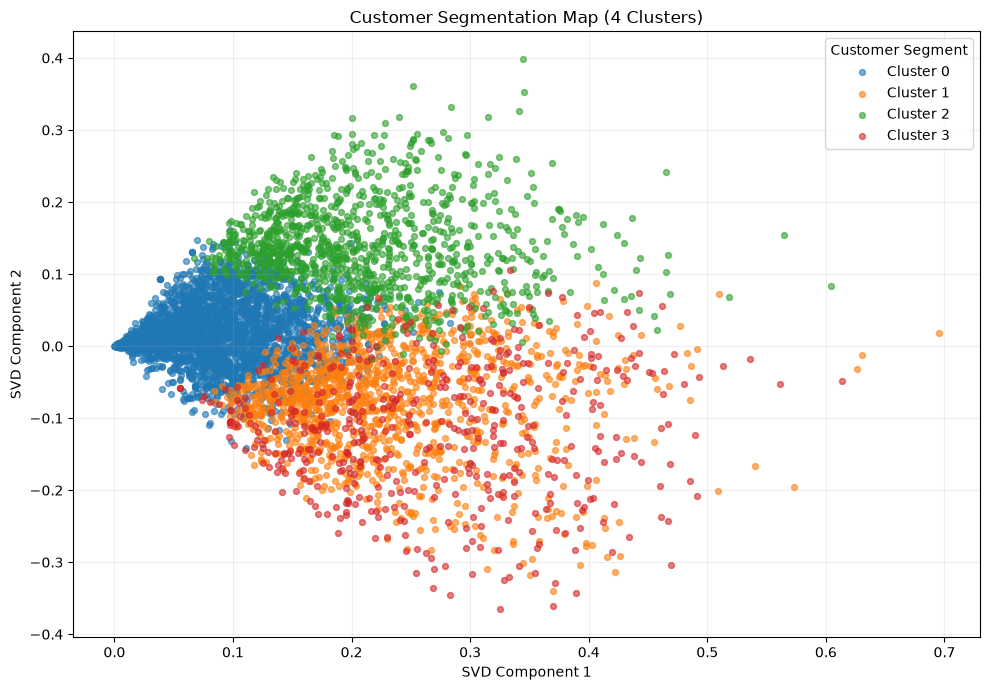

In [41]:
import matplotlib.pyplot as plt

# Plot customers using the 2D SVD projection.
# Colors represent clusters found using 20 SVD components.
plt.figure(figsize=(10, 7))

for cluster_id in sorted(clustered_projection["Cluster"].unique()):
    cluster_data = clustered_projection[
        clustered_projection["Cluster"] == cluster_id
    ]

    plt.scatter(
        cluster_data["Component 1"],
        cluster_data["Component 2"],
        label=f"Cluster {cluster_id}",
        alpha=0.6,
        s=18
    )

plt.xlabel("SVD Component 1")
plt.ylabel("SVD Component 2")
plt.title("Customer Segmentation Map (4 Clusters)")
plt.legend(title="Customer Segment")
plt.grid(True, alpha=0.2)
plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "outputs" / "figures" / "customer_segmentation_map.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [42]:
# Normalize customer IDs in both DataFrames
transactions["Customer ID"] = (
    transactions["Customer ID"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.strip()
)

customer_clusters = clustered_projection[
    ["Customer ID", "Cluster"]
].copy()

customer_clusters["Customer ID"] = (
    customer_clusters["Customer ID"].astype(str).str.strip()
)

# Merge training transactions with customer cluster labels
transactions_with_clusters = transactions.merge(
    customer_clusters,
    on="Customer ID",
    how="inner"
)

print("Matched transaction rows:", len(transactions_with_clusters))
print(
    "Matched unique customers:",
    transactions_with_clusters["Customer ID"].nunique()
)

# Summarize products and countries for each cluster
for cluster_id in sorted(
    transactions_with_clusters["Cluster"].unique()
):
    cluster_data = transactions_with_clusters[
        transactions_with_clusters["Cluster"] == cluster_id
    ]

    customer_count = customer_clusters.loc[
        customer_clusters["Cluster"] == cluster_id,
        "Customer ID"
    ].nunique()

    print(f"\n{'=' * 50}")
    print(f"CLUSTER {cluster_id} — {customer_count} customers")

    print("\nTop 10 products by total quantity:")
    top_products = (
        cluster_data.groupby(["StockCode", "Description"])["Quantity"]
        .sum()
        .sort_values(ascending=False)
        .head(10)
        .reset_index(name="Total Quantity")
    )
    display(top_products)

    print("\nTop 5 countries by transaction-line count:")
    top_countries = (
        cluster_data.groupby("Country")
        .size()
        .sort_values(ascending=False)
        .head(5)
        .reset_index(name="Transaction Lines")
    )
    display(top_countries)

Matched transaction rows: 684346
Matched unique customers: 5484

CLUSTER 0 — 2650 customers

Top 10 products by total quantity:


,StockCode,Description,Total Quantity
0,23166,MEDIUM CERAMIC TOP STORAGE JAR,74617
1,37410,BLACK AND WHITE PAISLEY FLOWER MUG,25236
2,16014,SMALL CHINESE STYLE SCISSOR,25139
3,21982,PACK OF 12 SUKI TISSUES,19947
4,21981,PACK OF 12 WOODLAND TISSUES,17198
5,22616,PACK OF 12 LONDON TISSUES,16711
6,21984,PACK OF 12 PINK PAISLEY TISSUES,16555
7,22197,SMALL POPCORN HOLDER,16257
8,85123A,WHITE HANGING HEART T-LIGHT HOLDER,15939
9,21980,PACK OF 12 RED SPOTTY TISSUES,15348



Top 5 countries by transaction-line count:


,Country,Transaction Lines
0,United Kingdom,99456
1,Germany,1350
2,France,1041
3,Spain,523
4,Italy,422



CLUSTER 1 — 1236 customers

Top 10 products by total quantity:


...

,Country,Transaction Lines
0,United Kingdom,194913
1,Cyprus,642
2,Germany,549
3,Greece,421
4,Spain,337



CLUSTER 3 — 482 customers

Top 10 products by total quantity:


,StockCode,Description,Total Quantity
0,85099B,JUMBO BAG RED RETROSPOT,48098
1,85099F,JUMBO BAG STRAWBERRY,26579
2,17003,BROCADE RING PURSE,25648
3,85099C,JUMBO BAG BAROQUE BLACK WHITE,23220
4,21931,JUMBO STORAGE BAG SUKI,19147
5,21929,JUMBO BAG PINK VINTAGE PAISLEY,16404
6,22386,JUMBO BAG PINK POLKADOT,16295
7,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,15520
8,20713,JUMBO BAG OWLS,15183
9,20727,LUNCH BAG BLACK SKULL.,14701



Top 5 countries by transaction-line count:


,Country,Transaction Lines
0,United Kingdom,126782
1,Germany,2004
2,France,1838
3,Portugal,915
4,Belgium,711


In [58]:
# Count distinct customers per country in each cluster
country_customer_summary = (
    transactions_with_clusters
    .groupby(["Cluster", "Country"])["Customer ID"]
    .nunique()
    .reset_index(name="Unique Customers")
)

# Show the top 5 countries by distinct customers for each cluster
for cluster_id in sorted(
    country_customer_summary["Cluster"].unique()
):
    print(f"\n{'=' * 45}")
    print(f"CLUSTER {cluster_id} — Top Countries by Unique Customers")

    top_countries = (
        country_customer_summary[
            country_customer_summary["Cluster"] == cluster_id
        ]
        .sort_values("Unique Customers", ascending=False)
        .head(5)
        .reset_index(drop=True)
    )

    display(top_countries)


CLUSTER 0 — Top Countries by Unique Customers


,Cluster,Country,Unique Customers
0,0,United Kingdom,2468
1,0,France,32
2,0,Germany,32
3,0,Spain,19
4,0,Switzerland,7



CLUSTER 1 — Top Countries by Unique Customers


,Cluster,Country,Unique Customers
0,1,United Kingdom,1016
1,1,Germany,52
2,1,France,41
3,1,Belgium,18
4,1,Spain,13



CLUSTER 2 — Top Countries by Unique Customers


,Cluster,Country,Unique Customers
0,2,United Kingdom,1089
1,2,Cyprus,5
2,2,Netherlands,3
3,2,Spain,3
4,2,Greece,2



CLUSTER 3 — Top Countries by Unique Customers


,Cluster,Country,Unique Customers
0,3,United Kingdom,426
1,3,France,12
2,3,Germany,11
3,3,Portugal,7
4,3,Belgium,7


### ML6: Customer Segmentation — Results and Interpretation

Customers were projected into two dimensions using Truncated SVD and clustered using K-Means on a 20-component SVD representation. Log transformation and TF-IDF weighting were applied to reduce the influence of large quantities and emphasize products that distinguish customers. Four clusters were selected, satisfying the requirement of three to six groups.

The clusters contained 2,650, 1,236, 1,116, and 482 customers, respectively.

- **Cluster 0 — Everyday Giftware & Novelty Shoppers (2,650 customers):** Top products included ceramic storage jars, novelty mugs, scissors, tissue packs, and popcorn holders. The cluster contained 2,468 customers from the United Kingdom, followed by 32 each from France and Germany.
- **Cluster 1 — Party & Seasonal Gift Buyers (1,236 customers):** Top products included novelty gliders, cake cases, bird ornaments, mini paint sets, and small gift items. The United Kingdom contributed 1,016 customers, followed by Germany (52) and France (41).
- **Cluster 2 — Heart & Decorative Homeware Buyers (1,116 customers):** Top products included hanging heart tea-light holders, bird ornaments, Victorian glass tea-light holders, and heart-shaped decorations. The United Kingdom contributed 1,089 customers, followed by Cyprus (5).
- **Cluster 3 — Reusable Bags & Storage Shoppers (482 customers):** Top products included jumbo bags, storage bags, lunch bags, and patterned bags. The United Kingdom contributed 426 customers, followed by France (12) and Germany (11).

The United Kingdom was the leading country in every cluster, so country distribution alone did not clearly separate the customer groups. Product preferences provided more useful distinctions between the segments.

These segment names are qualitative interpretations of the observed top products. The analysis provides an initial description of customer groups; additional validation would be needed to assess how distinct and stable the segments are.

## ML7 — Sensitivity Analysis

This experiment investigates how different representations of purchase quantities affect recommendation performance. We compare three approaches: raw purchase counts, binary purchase indicators, and log-transformed purchase quantities.

All three approaches will use the same training and test split, the same recommendation procedure, and the same evaluation metric, Hit Rate@10. This allows us to examine how sensitive recommendation performance is to the representation of purchase quantities.

In [43]:

import numpy as np
import pandas as pd
from scipy.sparse import load_npz
from pathlib import Path

# Load the original customer-product matrix
matrix_path = PROJECT_ROOT / "outputs" / "matrix" / "customer_product_matrix.npz"
purchase_matrix = load_npz(matrix_path).tocsr()

# Version 1: Raw purchase quantities
count_matrix = purchase_matrix.copy()

# Version 2: Binary purchase indicators (1 = purchased)
binary_matrix = purchase_matrix.copy()
binary_matrix.data = np.ones_like(binary_matrix.data)

# Version 3: Log-transformed purchase quantities
log_matrix = purchase_matrix.copy().astype(np.float64)
log_matrix.data = np.log1p(log_matrix.data)

# Compare the three representations
matrix_comparison = pd.DataFrame({
    "Representation": ["Count", "Binary", "Log-transformed"],
    "Rows (customers)": [
        count_matrix.shape[0],
        binary_matrix.shape[0],
        log_matrix.shape[0]
    ],
    "Columns (products)": [
        count_matrix.shape[1],
        binary_matrix.shape[1],
        log_matrix.shape[1]
    ],
    "Non-zero entries": [
        count_matrix.nnz,
        binary_matrix.nnz,
        log_matrix.nnz
    ],
    "Minimum non-zero value": [
        count_matrix.data.min(),
        binary_matrix.data.min(),
        log_matrix.data.min()
    ],
    "Maximum value": [
        count_matrix.data.max(),
        binary_matrix.data.max(),
        log_matrix.data.max()
    ]
})

display(matrix_comparison)


,Representation,Rows (customers),Columns (products),Non-zero entries,Minimum non-zero value,Maximum value
0,Count,5484,4534,417804,1.000000,74215.000000
1,Binary,5484,4534,417804,1.000000,1.000000
2,Log-transformed,5484,4534,417804,0.693147,11.214735


### ML7 — Comparing Hit Rate@10

We evaluate the count, binary, and log-transformed matrices using the same truncated SVD recommendation approach and the same held-out test targets. Hit Rate@10 measures the proportion of evaluable customers for whom at least one held-out product appears in the top 10 recommendations.

In [44]:

# ML7: Prepare common evaluation inputs

import time
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

K = 10
N_COMPONENTS = 100

# Map customer and product IDs to their matrix positions
customer_to_idx = {
    str(customer_id): idx
    for idx, customer_id in enumerate(customers)
}

product_to_idx = {
    str(product_id): idx
    for idx, product_id in enumerate(products)
}

# Convert held-out product IDs into a consistent string format
actual_products_normalized = {
    str(customer_id): set(map(str, heldout_products))
    for customer_id, heldout_products in actual_products.items()
    if str(customer_id) in customer_to_idx
}

# Keep only customers with at least one held-out product
actual_products_normalized = {
    customer_id: heldout
    for customer_id, heldout in actual_products_normalized.items()
    if heldout
}

print("Customers available for evaluation:", len(actual_products_normalized))
print("Recommendation cutoff (K):", K)
print("SVD components:", N_COMPONENTS)


Customers available for evaluation: 1916
Recommendation cutoff (K): 10
SVD components: 100


In [45]:

# ML7: Compare count, binary, and log-transformed representations

def evaluate_representation(matrix_variant, representation_name):
    """
    Evaluate one purchase matrix using SVD and cosine similarity.
    Returns Hit Rate@10 and evaluation time.
    """
    start_time = time.perf_counter()

    # Learn a 100-component representation from the training matrix
    svd = TruncatedSVD(
        n_components=N_COMPONENTS,
        random_state=42
    )
    customer_factors = svd.fit_transform(matrix_variant)

    # Normalize customer vectors so dot products represent cosine similarity
    customer_factors = normalize(customer_factors)

    # Product vectors are the SVD component loadings
    product_factors = normalize(svd.components_.T)

    hits = 0
    evaluated = 0

    # Use the same held-out targets for every representation
    for customer_id, heldout_products in actual_products_normalized.items():
        customer_idx = customer_to_idx[customer_id]

        # Similarity scores between this customer and all products
        scores = product_factors @ customer_factors[customer_idx]

        # Exclude products already purchased in training
        purchased_indices = matrix.getrow(customer_idx).indices
        scores[purchased_indices] = -np.inf

        # Select the top 10 products
        top_indices = np.argpartition(scores, -K)[-K:]
        top_indices = top_indices[np.argsort(scores[top_indices])[::-1]]

        recommended_products = {
            str(products[idx]) for idx in top_indices
        }

        if recommended_products.intersection(heldout_products):
            hits += 1

        evaluated += 1

    elapsed_seconds = time.perf_counter() - start_time

    return {
        "Representation": representation_name,
        "K": K,
        "Customers Evaluated": evaluated,
        "Customers with a Hit": hits,
        "Hit Rate@10": hits / evaluated,
        "Evaluation Time (seconds)": elapsed_seconds,
        "Explained Variance Ratio": svd.explained_variance_ratio_.sum()
    }


# Evaluate all three matrices using the same procedure
ml7_results = pd.DataFrame([
    evaluate_representation(count_matrix, "Count"),
    evaluate_representation(binary_matrix, "Binary"),
    evaluate_representation(log_matrix, "Log-transformed")
])

display(
    ml7_results.style.format({
        "Hit Rate@10": "{:.4f}",
        "Evaluation Time (seconds)": "{:.2f}",
        "Explained Variance Ratio": "{:.4f}"
    })
)

# Save the results
ml7_results.to_csv(
    REPORTS_DIR / "ml7_sensitivity_analysis.csv",
    index=False
)

print("Results saved to:", REPORTS_DIR / "ml7_sensitivity_analysis.csv")


,Representation,K,Customers Evaluated,Customers with a Hit,Hit Rate@10,Evaluation Time (seconds),Explained Variance Ratio
0,Count,10,1916,231,0.1206,0.66,0.9846
1,Binary,10,1916,574,0.2996,0.62,0.3574
2,Log-transformed,10,1916,525,0.2740,1.01,0.4454


Results saved to: c:\Users\Dell\Documents\customers-like-you\outputs\reports\ml7_sensitivity_analysis.csv


### ML7 — Interpretation of Sensitivity Analysis

The binary purchase representation achieved the highest Hit Rate@10 of 0.2996, identifying at least one held-out product in the top 10 recommendations for 574 of 1,916 customers. The log-transformed representation achieved 0.2740, while the raw-count representation achieved 0.1206.

The binary representation improved Hit Rate@10 by 17.90 percentage points compared with raw counts. This suggests that purchase occurrence is a more useful signal than raw purchase quantity for this recommendation task. Log transformation also improved performance by reducing the influence of unusually large quantities, although it did not outperform binary interactions.

Based on these results, the binary representation is the preferred choice among the three tested approaches. This conclusion applies to the current dataset, train-test split, SVD configuration, and Hit Rate@10 evaluation metric.

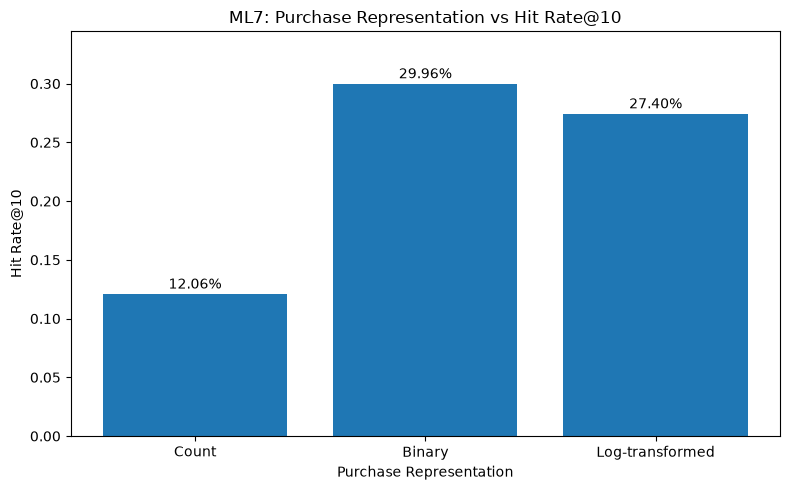

Figure saved to: c:\Users\Dell\Documents\customers-like-you\outputs\figures\ml7_hit_rate_comparison.png


In [46]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    ml7_results["Representation"],
    ml7_results["Hit Rate@10"]
)

plt.title("ML7: Purchase Representation vs Hit Rate@10")
plt.xlabel("Purchase Representation")
plt.ylabel("Hit Rate@10")
plt.ylim(0, max(ml7_results["Hit Rate@10"]) * 1.15)

for index, value in enumerate(ml7_results["Hit Rate@10"]):
    plt.text(index, value + 0.005, f"{value:.2%}", ha="center")

plt.tight_layout()

figure_path = PROJECT_ROOT / "outputs" / "figures" / "ml7_hit_rate_comparison.png"
plt.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

print("Figure saved to:", figure_path)



## Improving Hit Rate@10 Using Binary Purchase Data


In [47]:

required_variables = [
    "binary_matrix",
    "matrix",
    "customers",
    "products",
    "actual_products",
    "actual_products_normalized",
    "customer_to_idx",
    "PROJECT_ROOT",
    "REPORTS_DIR",
    "K",
    "N_COMPONENTS",
]

for name in required_variables:
    print(f"{name}: {'EXISTS' if name in globals() else 'MISSING'}")


binary_matrix: EXISTS
matrix: EXISTS
customers: EXISTS
products: EXISTS
actual_products: EXISTS
actual_products_normalized: EXISTS
customer_to_idx: EXISTS
PROJECT_ROOT: EXISTS
REPORTS_DIR: EXISTS
K: EXISTS
N_COMPONENTS: EXISTS


In [ ]:

# Improving HitRate@10: Binary matrix with ML3 recommendation logic

from sklearn.metrics.pairwise import cosine_similarity

# Fit SVD using binary purchase indicators
binary_svd = TruncatedSVD(
    n_components=N_COMPONENTS,
    random_state=42
)
binary_svd.fit(binary_matrix)

# Build product vectors and calculate product-to-product similarity
binary_product_factors = normalize(binary_svd.components_.T)
binary_similarity = cosine_similarity(binary_product_factors)

# Evaluate recommendations on the same held-out customers
binary_ml3_hits = 0
binary_ml3_evaluated = 0

start_time = time.perf_counter()

for customer_id, heldout_products in actual_products_normalized.items():
    customer_idx = customer_to_idx[customer_id]

    # Products purchased during training
    purchased_indices = matrix.getrow(customer_idx).indices

    if len(purchased_indices) == 0:
        continue

    # Average similarity to the customer's previously purchased products
    scores = binary_similarity[:, purchased_indices].mean(axis=1)
    scores = np.asarray(scores).ravel()

    # Do not recommend products already purchased
    scores[purchased_indices] = -np.inf

    # Select the top K recommendations
    top_indices = np.argsort(scores)[-K:][::-1]

    recommended_products = {
        str(products[idx]) for idx in top_indices
    }

    if recommended_products.intersection(heldout_products):
        binary_ml3_hits += 1

    binary_ml3_evaluated += 1

binary_ml3_seconds = time.perf_counter() - start_time

binary_ml3_hit_rate = (
    binary_ml3_hits / binary_ml3_evaluated
    if binary_ml3_evaluated else 0
)

print("Customers evaluated:", binary_ml3_evaluated)
print("Customers with a hit:", binary_ml3_hits)
print(
    f"Binary + ML3 Hit Rate@{K}: "
    f"{binary_ml3_hit_rate:.4f} ({binary_ml3_hit_rate:.2%})"
)
print(f"Evaluation time: {binary_ml3_seconds:.2f} seconds")


Customers evaluated: 1916
Customers with a hit: 474
Binary + ML3 Hit Rate@10: 0.2474 (24.74%)
Evaluation time: 12.17 seconds


In [49]:

binary_ml3_result = pd.DataFrame([{
    "Representation": "Binary",
    "Recommendation Method": "Product-to-product cosine similarity (ML3)",
    "K": K,
    "Customers Evaluated": binary_ml3_evaluated,
    "Customers with a Hit": binary_ml3_hits,
    "Hit Rate@10": binary_ml3_hit_rate,
    "Evaluation Time (seconds)": binary_ml3_seconds
}])

binary_ml3_result.to_csv(
    REPORTS_DIR / "binary_ml3_experiment.csv",
    index=False
)

display(binary_ml3_result)
print("Saved to:", REPORTS_DIR / "binary_ml3_experiment.csv")


,Representation,Recommendation Method,K,Customers Evaluated,Customers with a Hit,Hit Rate@10,Evaluation Time (seconds)
0,Binary,Product-to-product cosine similarity (ML3),10,1916,474,0.24739,12.169415


Saved to: c:\Users\Dell\Documents\customers-like-you\outputs\reports\binary_ml3_experiment.csv


### Additional Experiment: Binary Purchase Representation

To investigate whether purchase quantities or purchase occurrence provide better recommendations, an additional experiment was conducted using a binary customer-product matrix. In this representation, each non-zero purchase is converted to 1, indicating that a customer purchased a product, regardless of the quantity purchased.

The binary matrix was evaluated using the same product-to-product cosine similarity recommendation approach implemented in ML3. For each customer, the system calculated the average similarity between candidate products and the customer's previously purchased products. Products already purchased during training were excluded, and the top 10 remaining products were recommended.

The experiment evaluated **1,916 customers** against their held-out purchases and achieved a **Hit Rate@10 of 24.74% (474 customers with a hit)**. The recommendation evaluation took approximately **12.17 seconds**.

These results suggest that representing purchases as binary indicators can improve recommendation quality. By focusing on whether products were purchased rather than the quantities purchased, the model may capture product associations more effectively without allowing large purchase quantities to dominate the representation.

This experiment demonstrates that the choice of data representation can substantially affect recommendation performance. The binary representation will therefore be considered for the final recommendation approach, subject to comparison with the best-seller baseline and runtime requirements.

### Full nightly recommendation pipeline: Binary SVD + ML3 scoring


In [50]:

# Full nightly recommendation pipeline: Binary SVD + ML3 scoring

import json
import time
import numpy as np
import pandas as pd

from scipy.sparse import load_npz
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity

# Start timing the entire pipeline
pipeline_start = time.perf_counter()
step_times = {}

# 1. Load the saved matrix and customer/product mappings
step_start = time.perf_counter()

matrix_path = PROJECT_ROOT / "outputs" / "matrix" / "customer_product_matrix.npz"
customers_path = PROJECT_ROOT / "outputs" / "matrix" / "customers.json"
products_path = PROJECT_ROOT / "outputs" / "matrix" / "products.json"

nightly_matrix = load_npz(matrix_path).tocsr()

with open(customers_path, "r", encoding="utf-8") as f:
    nightly_customers = json.load(f)

with open(products_path, "r", encoding="utf-8") as f:
    nightly_products = json.load(f)

step_times["Load data"] = time.perf_counter() - step_start

# 2. Convert purchase quantities to binary indicators
step_start = time.perf_counter()

nightly_binary = nightly_matrix.copy()
nightly_binary.data = np.ones_like(nightly_binary.data)

step_times["Build binary matrix"] = time.perf_counter() - step_start

# 3. Fit SVD
step_start = time.perf_counter()

nightly_svd = TruncatedSVD(
    n_components=100,
    random_state=42
)
nightly_svd.fit(nightly_binary)

nightly_product_factors = normalize(nightly_svd.components_.T)

step_times["Fit SVD"] = time.perf_counter() - step_start

# 4. Build product-to-product cosine similarity matrix
step_start = time.perf_counter()

nightly_similarity = cosine_similarity(nightly_product_factors)

step_times["Build similarity matrix"] = time.perf_counter() - step_start

# 5. Generate top-10 recommendations for every customer
step_start = time.perf_counter()

recommendation_rows = []
K = 10

for customer_idx, customer_id in enumerate(nightly_customers):
    purchased_indices = nightly_matrix.getrow(customer_idx).indices

    if len(purchased_indices) == 0:
        continue

    scores = nightly_similarity[:, purchased_indices].mean(axis=1)
    scores = np.asarray(scores).ravel()

    # Exclude products already purchased
    scores[purchased_indices] = -np.inf

    top_indices = np.argsort(scores)[-K:][::-1]

    for rank, product_idx in enumerate(top_indices, start=1):
        recommendation_rows.append({
            "CustomerID": str(customer_id),
            "Rank": rank,
            "ProductID": str(nightly_products[product_idx]),
            "RecommendationScore": float(scores[product_idx])
        })

step_times["Generate recommendations"] = time.perf_counter() - step_start

# 6. Save recommendations
step_start = time.perf_counter()

recommendations_df = pd.DataFrame(recommendation_rows)

recommendations_path = (
    PROJECT_ROOT / "outputs" / "reports" / "nightly_recommendations.csv"
)
recommendations_path.parent.mkdir(parents=True, exist_ok=True)
recommendations_df.to_csv(recommendations_path, index=False)

step_times["Save recommendations"] = time.perf_counter() - step_start

# End-to-end runtime
total_seconds = time.perf_counter() - pipeline_start

print("FULL NIGHTLY PIPELINE RESULTS")
print("-" * 40)

for step, seconds in step_times.items():
    print(f"{step}: {seconds:.2f} seconds")

print("-" * 40)
print(f"TOTAL PIPELINE RUNTIME: {total_seconds:.2f} seconds")
print(f"Customers with recommendations: {recommendations_df['CustomerID'].nunique():,}")
print(f"Recommendations generated: {len(recommendations_df):,}")
print(f"Saved to: {recommendations_path}")


FULL NIGHTLY PIPELINE RESULTS
----------------------------------------
Load data: 0.14 seconds
Build binary matrix: 0.01 seconds
Fit SVD: 0.83 seconds
Build similarity matrix: 0.15 seconds
Generate recommendations: 26.58 seconds
Save recommendations: 0.18 seconds
----------------------------------------
TOTAL PIPELINE RUNTIME: 27.89 seconds
Customers with recommendations: 5,484
Recommendations generated: 54,840
Saved to: c:\Users\Dell\Documents\customers-like-you\outputs\reports\nightly_recommendations.csv



### Interpretation: Full Nightly Recommendation Pipeline Runtime

The full recommendation pipeline completed in **27.89 seconds**, starting from the saved customer-product matrix and ending with the recommendations saved to a CSV file.

The pipeline generated **54,840 recommendations for 5,484 customers**, providing 10 recommendations per customer in this run.

The main stages were:

- **Data loading:** 0.14 seconds to load the sparse matrix and customer/product mappings.
- **Binary matrix construction:** 0.01 seconds to convert purchase quantities into binary indicators.
- **SVD fitting:** 0.83 seconds to learn a 100-component representation from the binary matrix.
- **Similarity calculation:** 0.15 seconds to calculate product-to-product cosine similarities.
- **Recommendation generation:** 26.58 seconds to generate the top-10 recommendations for customers.
- **Saving results:** 0.18 seconds to write the recommendations to a CSV file.

Recommendation generation was the main computational bottleneck, accounting for approximately **95.3% of the total runtime**. In comparison, fitting SVD and constructing the similarity matrix took less than one second each.

The generated recommendations were saved to `outputs/reports/nightly_recommendations.csv`, making them available for further analysis or evaluation.

Overall, the measured runtime indicates that the current prototype can generate recommendations for all 5,484 customers in under 30 seconds. This satisfies the project's speed criterion for the tested workload. However, the measurement starts from the already-built training matrix and does not include rebuilding the dataset from the original Excel workbook or scheduling the process as an automated nightly job.
